# Economic Value Added and Market Value Added for the S&P 500: ROIC, WACC and EVA from SEC Filings since 2010, R&D Capitalisation, and Whether Value Creation Explains Market Value and Future Returns Better than Earnings

Accounting profit ignores the cost of equity. A company that earns USD 1 billion on USD 20 billion of capital looks profitable, but if its investors expect 9% a year it is destroying value. **Economic Value Added** (EVA), popularised by Stern Stewart & Co. in the 1990s, charges every company for all the capital it uses:

EVA = NOPAT − WACC × Invested capital = (ROIC − WACC) × Invested capital

**Market Value Added** (MVA) is what the market thinks of it: the market value of the company's debt and equity minus the capital invested. In theory, MVA equals the present value of all future EVA, so a firm with a positive spread between its return on invested capital (ROIC) and its weighted average cost of capital (WACC) should trade above its invested capital.

This notebook computes both for the non-financial companies of the S&P 500 from their own 10-K filings since fiscal 2010, and tests the claims made for EVA:

- **Who creates value?** ROIC, WACC and EVA by company, sector and year, and how persistent the spread between ROIC and WACC is.
- **R&D capitalisation**, the best-known EVA adjustment: research spending is treated as an investment amortised over five years instead of an expense.
- **Does EVA explain market value better than earnings?** Cross-sectional regressions and out-of-time ridge, k-nearest-neighbour and LightGBM models of the market-to-capital ratio, with EVA measures, earnings measures or both.
- **Does it predict returns?** Fama–MacBeth regressions and out-of-time models of the next year's stock return after the 10-K is filed, the test that Biddle, Bowen and Wallace (1997) made famous.

**Data.** SEC EDGAR XBRL company facts (10-K income statements and balance sheets as first filed, shares outstanding); iShares Core S&P 500 ETF holdings (constituents and sectors); Yahoo Finance (prices, dividends and splits); FRED (10-year Treasury yield).

**Methods.** NOPAT and operating invested capital, effective tax rates, CAPM cost of equity with Blume-adjusted betas, after-tax cost of debt, market-value weights, EVA and MVA, R&D capitalisation, quintile transition matrices and AR(1) persistence, cross-sectional OLS and Fama–MacBeth regressions, ridge, k-nearest-neighbour and LightGBM regression, out-of-time R² and rank correlation.

**Key output.** ROIC, WACC, EVA and MVA for each company and year; the sector map of value creation; how R&D capitalisation changes the picture; and which measures explain market value and future returns.

## 1. From the 10-K to EVA

| Quantity | Definition used here | XBRL elements |
|---|---|---|
| **Invested capital** (operating approach) | total assets − cash and short-term investments − non-interest-bearing current liabilities | `Assets`, `CashAndCashEquivalentsAtCarryingValue`, `MarketableSecuritiesCurrent` / `ShortTermInvestments`, `LiabilitiesCurrent` minus `LongTermDebtCurrent` / `DebtCurrent`, `ShortTermBorrowings` |
| **NOPAT** | operating income × (1 − effective tax rate) | `OperatingIncomeLoss`, `IncomeTaxExpenseBenefit`, pre-tax income |
| **ROIC** | NOPAT ÷ average invested capital of the year | |
| **Cost of equity** | 10-year Treasury yield + β × 5% equity risk premium; β from 60 monthly returns against the S&P 500, Blume-adjusted (0.67 β + 0.33) | |
| **Cost of debt** | interest expense ÷ average debt, bounded between the Treasury yield and the yield + 6%, × (1 − statutory tax rate) | `InterestExpense`, `LongTermDebt…`, `DebtCurrent` |
| **WACC** | weights from the market value of equity and the book value of debt at fiscal year-end | `EntityCommonStockSharesOutstanding` × price (diluted weighted shares when the cover-page figure is off by more than half) |
| **EVA** | (ROIC − WACC) × average invested capital | |
| **MVA** | market value of equity + debt − invested capital | |

The operating approach measures capital from the asset side. It works even for the many S&P 500 companies whose book equity is small or negative after years of buybacks (Home Depot, McDonald's, Starbucks), where an equity-plus-debt definition breaks down. Every value is taken from the 10-K **as first filed**, so later restatements do not leak into the past.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import io

import lightgbm as lgb
import yfinance as yf
from scipy import stats
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
rng = np.random.default_rng(SEED)
SEC_HEADERS = {"User-Agent": os.getenv("SEC_USER_AGENT", "").strip()}
if not SEC_HEADERS["User-Agent"]:
    raise RuntimeError(
        "SEC_USER_AGENT missing in .env (the SEC asks automated clients to"
        " identify themselves)."
    )
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}
IVV_URL = "https://www.ishares.com/us/products/239726/fund/latest-holdings.csv"
# banks and REITs: invested capital and NOPAT mean something else
EXCLUDE_SECTORS = {"Financials", "Real Estate"}
FIRST_FY, LAST_FY = 2010, 2025
ERP = 0.05  # equity risk premium
# cost of debt bounded between the Treasury yield and yield + 6%
DEBT_SPREAD_CAP = 0.06
# years over which capitalised R&D is amortised
RD_LIFE = 5
# models trained on fiscal years up to 2018, tested from 2019
TRAIN_LAST_FY = 2018
FLOW = {
    "revenue": [
        "Revenues",
        "RevenueFromContractWithCustomerExcludingAssessedTax",
        "SalesRevenueNet",
    ],
    "ebit": ["OperatingIncomeLoss"],
    "pretax": [
        "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest",
        "IncomeLossFromContinuingOperationsBeforeIncomeTaxesMinorityInterestAndIncomeLossFromEquityMethodInvestments",
    ],
    "tax": ["IncomeTaxExpenseBenefit"],
    "interest": [
        "InterestExpense",
        "InterestExpenseNonoperating",
        "InterestExpenseDebt",
    ],
    "net_income": ["NetIncomeLoss"],
    "rnd": [
        "ResearchAndDevelopmentExpense",
        "ResearchAndDevelopmentExpenseExcludingAcquiredInProcessCost",
    ],
}
INSTANT = {
    "assets": ["Assets"],
    "cash": ["CashAndCashEquivalentsAtCarryingValue"],
    "st_inv": [
        "MarketableSecuritiesCurrent",
        "ShortTermInvestments",
        "AvailableForSaleSecuritiesDebtSecuritiesCurrent",
    ],
    "liab_cur": ["LiabilitiesCurrent"],
    "ltd_nc": ["LongTermDebtNoncurrent"],
    "ltd": ["LongTermDebt"],
    "debt_cur": ["LongTermDebtCurrent", "DebtCurrent"],
    "stb": ["ShortTermBorrowings", "CommercialPaper"],
    "equity": ["StockholdersEquity"],
}

print(
    f"yfinance {yf.__version__} · lightgbm {lgb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

yfinance 1.7.0 · lightgbm 4.7.0 · run on 2026-11-11


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

The universe is today's S&P 500 (from the holdings of the iShares Core S&P 500 ETF) without financials and real estate. Using today's members means the sample includes only firms that survived and grew enough to be in the index now, which flatters value creation in the early years. That bias is kept in mind below.

In [3]:
def sec_json(url):
    r = requests.get(url, headers=SEC_HEADERS, timeout=120)
    r.raise_for_status()
    return r.json()


def fetch_ivv():
    lines = requests.get(
        IVV_URL, headers=BROWSER_HEADERS, timeout=60
    ).text.splitlines()
    header = next(i for i, l in enumerate(lines) if l.startswith("Ticker"))
    t = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    return t[t["Asset Class"] == "Equity"][["Ticker", "Name", "Sector"]]


IVV = cached("ivv_holdings", fetch_ivv, max_age_hours=24 * 7)
tick = pd.DataFrame(
    sec_json("https://www.sec.gov/files/company_tickers.json")
).T
cik_of = {
    t.replace(".", "-"): int(c) for t, c in zip(tick.ticker, tick.cik_str)
}
UNI = IVV[~IVV.Sector.isin(EXCLUDE_SECTORS)].copy()
UNI["yf"] = UNI.Ticker.str.replace(".", "-", regex=False).str.replace(
    " ", "-", regex=False
)
UNI["cik"] = UNI.yf.map(cik_of)
UNI = UNI.dropna(subset=["cik"]).drop_duplicates("cik")
UNI["cik"] = UNI.cik.astype(int)
print(
    f"{len(IVV)} S&P 500 holdings · {len(UNI)} non-financial companies with an"
    " SEC CIK"
)
UNI.Sector.value_counts().to_frame("companies").T

505 S&P 500 holdings · 394 non-financial companies with an SEC CIK


Sector,Industrials,Information Technology,Health Care,Consumer Discretionary,Consumer Staples,Utilities,Materials,Energy,Communication
companies,83,76,60,47,33,31,24,21,19


In [4]:
def fetch_facts():
    rows = []
    for _, u in UNI.iterrows():
        try:
            f = sec_json(
                f"https://data.sec.gov/api/xbrl/companyfacts/CIK{u.cik:010d}.json"
            )["facts"]
        except requests.HTTPError:
            continue
        for item, tags in {**FLOW, **INSTANT}.items():
            for tag in tags:
                v = (
                    f.get("us-gaap", {})
                    .get(tag, {})
                    .get("units", {})
                    .get("USD")
                )
                if v:
                    d = pd.DataFrame(v)
                    d = d[d.form.isin(["10-K", "10-K/A"])]
                    rows.append(
                        d.reindex(
                            columns=["start", "end", "val", "filed", "form"]
                        ).assign(cik=u.cik, item=item, tag=tag)
                    )
        dil = (
            f.get("us-gaap", {})
            .get("WeightedAverageNumberOfDilutedSharesOutstanding", {})
            .get("units", {})
            .get("shares")
        )
        if dil:
            d = pd.DataFrame(dil)
            d = d[d.form.isin(["10-K", "10-K/A"])]
            rows.append(
                d.reindex(
                    columns=["start", "end", "val", "filed", "form"]
                ).assign(
                    cik=u.cik,
                    item="shares_dil",
                    tag="WeightedAverageNumberOfDilutedSharesOutstanding",
                )
            )
        sh = (
            f.get("dei", {})
            .get("EntityCommonStockSharesOutstanding", {})
            .get("units", {})
            .get("shares")
        )
        if sh:
            d = pd.DataFrame(sh)
            d = d[d.form.isin(["10-K", "10-K/A"])]
            rows.append(
                d.reindex(
                    columns=["start", "end", "val", "filed", "form"]
                ).assign(cik=u.cik, item="shares", tag="dei")
            )
        time.sleep(0.12)
    return pd.concat(rows, ignore_index=True)


def fetch_prices():
    px = yf.download(
        UNI.yf.tolist() + ["SPY"],
        start="2004-01-01",
        auto_adjust=False,
        actions=True,
        progress=False,
        threads=True,
    )
    return pd.concat(
        {k: px[k] for k in ["Adj Close", "Close", "Stock Splits"]}, axis=1
    )


t0 = time.time()
FACTS = cached("sec_10k_facts", fetch_facts, max_age_hours=24 * 7)
PX = cached("yahoo_prices", fetch_prices, max_age_hours=24 * 7)
UST = (
    cached(
        "fred_dgs10",
        lambda: fred.get_series(
            "DGS10", observation_start="2004-01-01"
        ).to_frame("dgs10"),
        max_age_hours=24 * 7,
    ).dgs10
    / 100
)
PX.index = pd.to_datetime(PX.index)
ADJ, CLOSE, SPLIT = (
    PX["Adj Close"],
    PX["Close"],
    PX["Stock Splits"].replace(0, 1).fillna(1),
)
# traded prices, undoing later splits
RAW = CLOSE * SPLIT[::-1].cumprod()[::-1].shift(-1).fillna(1)
print(
    f"{len(FACTS):,} 10-K facts for {FACTS.cik.nunique()} companies · prices"
    f" for {ADJ.notna().any().sum()} tickers · {time.time() - t0:.0f} s"
)

282,643 10-K facts for 391 companies · prices for 395 tickers · 0 s


In [5]:
F = FACTS.assign(
    start=pd.to_datetime(FACTS.start),
    end=pd.to_datetime(FACTS.end),
    filed=pd.to_datetime(FACTS.filed),
)
# value as first filed
F = F.sort_values("filed").drop_duplicates(
    ["cik", "tag", "start", "end"], keep="first"
)
pref = {
    t: i for tags in {**FLOW, **INSTANT}.values() for i, t in enumerate(tags)
} | {"dei": 0, "WeightedAverageNumberOfDilutedSharesOutstanding": 0}
F["rank"] = F.tag.map(pref)

# annual flows: durations of 350–380 days
fl = F[
    F.item.isin(list(FLOW) + ["shares_dil"])
    & ((F.end - F.start).dt.days.between(350, 380))
]
fl = fl.sort_values("rank").drop_duplicates(["cik", "item", "end"])
FL = fl.pivot_table(
    index=["cik", "end"], columns="item", values="val", aggfunc="first"
)
FL["filed"] = fl.groupby(["cik", "end"]).filed.min()
FL = FL.reset_index()
# fiscal-year convention
FL["fy"] = np.where(FL.end.dt.month >= 6, FL.end.dt.year, FL.end.dt.year - 1)
FL = (
    FL[FL.fy.between(FIRST_FY - RD_LIFE, LAST_FY)]
    .sort_values("filed")
    .drop_duplicates(["cik", "fy"], keep="last")
)

# balance sheets at each fiscal year-end
ins = (
    F[F.item.isin(INSTANT)]
    .sort_values("rank")
    .drop_duplicates(["cik", "item", "end"])
)
IN = ins.pivot_table(
    index=["cik", "end"], columns="item", values="val", aggfunc="first"
).reset_index()
sh = F[F.item == "shares"].sort_values("filed").drop_duplicates(["cik", "end"])
P = FL.merge(IN, on=["cik", "end"], how="left").sort_values(["cik", "fy"])
P["shares"] = [
    (
        sh[
            (sh.cik == c)
            & (sh.filed >= f - pd.Timedelta(days=5))
            & (sh.filed <= f + pd.Timedelta(days=5))
        ].val.max()
        if pd.notna(f)
        else np.nan
    )
    # cover-page shares of the same 10-K
    for c, f in zip(P.cik, P.filed)
]
ratio = P.shares / P.shares_dil
# tagging errors (e.g. thousands vs units) fall back to diluted shares
P["shares"] = P.shares.where(ratio.between(0.67, 1.5), P.shares_dil)
P = P.merge(UNI[["cik", "yf", "Name", "Sector"]], on="cik", how="left")
for c in ["cash", "debt_cur", "stb", "ltd_nc", "ltd", "rnd", "interest"]:
    P[c] = P[c].fillna(0) if c in ["stb", "rnd"] else P[c]
P["debt"] = (
    np.where(
        P.ltd_nc.notna(), P.ltd_nc + P.debt_cur.fillna(0), P.ltd.fillna(0)
    )
    + P.stb
)
P["ic"] = (
    P.assets
    - P.cash.fillna(0)
    - P.st_inv.fillna(0)
    - (P.liab_cur - P.debt_cur.fillna(0) - P.stb).clip(lower=0)
)
print(
    f"{len(P):,} company-years · {P.cik.nunique()} companies · fiscal"
    f" {P.fy.min()}–{P.fy.max()} · missing: operating income"
    f" {P.ebit.isna().mean():.1%}, current liabilities"
    f" {P.liab_cur.isna().mean():.1%}, shares {P.shares.isna().mean():.1%}"
)

6,555 company-years · 391 companies · fiscal 2006–2025 · missing: operating income 13.0%, current liabilities 8.1%, shares 4.6%


## 4. ROIC, WACC, EVA and MVA

In [6]:
def price_at(t, d):
    s = RAW[t].loc[:d].dropna() if t in RAW else pd.Series(dtype=float)
    return s.iloc[-1] if len(s) and (d - s.index[-1]).days < 10 else np.nan


MRET = ADJ.resample("ME").last().pct_change()


def beta_at(t, d):
    if t not in MRET:
        return np.nan
    w = MRET.loc[:d, [t, "SPY"]].dropna().iloc[-60:]
    if len(w) < 36:
        return np.nan
    b = w[t].cov(w.SPY) / w.SPY.var()
    return 0.67 * b + 0.33


P = P.sort_values(["cik", "fy"])
lag = P.groupby("cik").shift(1)
cont = (P.fy - lag.fy) == 1
P["ic_avg"] = np.where(cont & (lag.ic > 0), (P.ic + lag.ic) / 2, P.ic)
P["debt_avg"] = np.where(cont, (P.debt + lag.debt) / 2, P.debt)
P["stat_tax"] = np.where(P.end >= "2018-01-01", 0.21, 0.35)
eff = (P.tax / P.pretax).where(P.pretax > 0)
P["tax_rate"] = eff.clip(0, 0.40).fillna(P.stat_tax)
P["nopat"] = P.ebit * (1 - P.tax_rate)
P["roic"] = P.nopat / P.ic_avg
P["price"] = [price_at(t, d) for t, d in zip(P.yf, P.end)]
P["mv_equity"] = P.shares * P.price
P["rf"] = [UST.loc[:d].dropna().iloc[-1] for d in P.end]
P["beta"] = [beta_at(t, d) for t, d in zip(P.yf, P.end)]
P["ke"] = P.rf + P.beta * ERP
P["kd_pre"] = (P.interest / P.debt_avg).where(P.debt_avg > 0)
P["kd_pre"] = P.kd_pre.clip(lower=P.rf, upper=P.rf + DEBT_SPREAD_CAP).fillna(
    P.rf + 0.01
)
P["kd"] = P.kd_pre * (1 - P.stat_tax)
P["we"] = P.mv_equity / (P.mv_equity + P.debt)
P["wacc"] = P.we * P.ke + (1 - P.we) * P.kd
P["spread"] = P.roic - P.wacc
# USD bn
P["eva"] = P.spread * P.ic_avg / 1e9
P["mva"] = (P.mv_equity + P.debt - P.ic) / 1e9
# market-to-capital
P["mtc"] = (P.mv_equity + P.debt) / P.ic
ok = (
    P.fy.between(FIRST_FY, LAST_FY)
    & (P.ic > 0.05 * P.assets)
    & P.roic.notna()
    & P.wacc.notna()
    & P.mv_equity.notna()
)
E = P[ok].copy()
E = E[E.roic.between(-1, 3)]
print(
    f"{len(E):,} company-years with EVA ({E.cik.nunique()} companies) · median"
    f" ROIC {E.roic.median():.1%}, median WACC {E.wacc.median():.1%}, share"
    f" with ROIC > WACC {(E.spread > 0).mean():.0%}"
)
YR = E.groupby("fy").agg(
    companies=("cik", "size"),
    median_roic=("roic", "median"),
    median_wacc=("wacc", "median"),
    share_creating=("spread", lambda s: (s > 0).mean()),
    eva_total_bn=("eva", "sum"),
    mva_total_bn=("mva", "sum"),
)
YR.round(3)

4,582 company-years with EVA (342 companies) · median ROIC 11.6%, median WACC 7.1%, share with ROIC > WACC 71%


,companies,median_roic,median_wacc,share_creating,eva_total_bn,mva_total_bn
fy,,,,,,
2010,241,0.13,0.08,0.73,148.27,"2,750.01"
2011,249,0.13,0.07,0.81,206.45,"2,905.35"
2012,255,0.12,0.06,0.75,187.96,"3,510.49"
2013,258,0.12,0.07,0.74,184.66,"4,839.34"
2014,266,0.12,0.07,0.76,202.95,"5,644.79"
2015,263,0.11,0.07,0.76,177.89,"5,559.48"
2016,277,0.11,0.07,0.71,182.35,"6,446.13"
2017,284,0.11,0.07,0.75,236.13,"8,922.06"
2018,291,0.12,0.07,0.73,260.68,"8,883.09"


In [7]:
LFY = int(E.fy.max())
last = E[E.fy == LFY]
SECT = last.groupby("Sector").agg(
    companies=("cik", "size"),
    median_roic=("roic", "median"),
    median_wacc=("wacc", "median"),
    share_creating=("spread", lambda s: (s > 0).mean()),
    eva_bn=("eva", "sum"),
    mva_bn=("mva", "sum"),
)
print(
    f"Fiscal {LFY}: total EVA USD {last.eva.sum():,.0f} bn, total MVA USD"
    f" {last.mva.sum() / 1e3:,.1f} trillion"
)
display(SECT.sort_values("eva_bn", ascending=False).round(3))
TOPBOT = pd.concat([last.nlargest(10, "eva"), last.nsmallest(8, "eva")])[
    ["Name", "Sector", "roic", "wacc", "ic_avg", "eva", "mva"]
]
TOPBOT.assign(ic_avg=TOPBOT.ic_avg / 1e9).round(3)

Fiscal 2025: total EVA USD 506 bn, total MVA USD 36.9 trillion


,companies,median_roic,median_wacc,share_creating,eva_bn,mva_bn
Sector,,,,,,
Information Technology,69,0.15,0.09,0.64,308.85,"17,491.98"
Communication,14,0.07,0.09,0.64,109.63,"5,528.34"
Consumer Staples,25,0.12,0.07,0.68,43.76,"2,522.84"
Industrials,69,0.13,0.09,0.72,43.19,"3,041.87"
Consumer Discretionary,38,0.18,0.09,0.79,24.52,"5,043.49"
Health Care,49,0.11,0.08,0.69,19.00,"2,605.79"
Energy,13,0.08,0.07,0.61,0.77,143.12
Materials,15,0.08,0.09,0.33,-8.91,383.08
Utilities,29,0.04,0.06,0.03,-35.19,107.83


,Name,Sector,roic,wacc,ic_avg,eva,mva
2104,APPLE,Information Technology,0.74,0.09,151.77,97.99,"3,714.18"
4351,NVIDIA,Information Technology,1.03,0.14,107.69,96.05,"4,403.81"
6245,ALPHABET CLASS A,Communication,0.34,0.09,318.23,77.53,"3,508.84"
2656,MICROSOFT,Information Technology,0.30,0.09,353.25,73.06,"3,354.26"
5396,META PLATFORMS CLASS A,Communication,0.29,0.10,203.62,38.45,"1,515.22"
4071,AMAZON.COM INC,Consumer Discretionary,0.15,0.10,414.82,21.90,"2,066.47"
6384,BROADCOM INC,Information Technology,0.18,0.10,140.20,11.84,"1,612.96"
2159,HOME DEPOT,Consumer Discretionary,0.22,0.09,70.93,9.66,351.21
1399,PROCTER & GAMBLE,Consumer Staples,0.17,0.07,97.28,9.55,309.01
5688,PHILIP MORRIS INTERNATIONAL,Consumer Staples,0.32,0.07,36.92,9.31,210.81


## 5. Is value creation persistent?

If competition erodes excess returns, the spread between ROIC and WACC should revert towards zero. Two views: the probability that a company in each spread quintile is still there three years later, and the AR(1) coefficient of the spread from one year to the next.

In [8]:
E = E.sort_values(["cik", "fy"])
E["q"] = E.groupby("fy").spread.transform(
    lambda s: pd.qcut(s, 5, labels=False) + 1
)
fut = (
    E[["cik", "fy", "q", "spread"]]
    .assign(fy=E.fy - 3)
    .rename(columns={"q": "q3", "spread": "spread3"})
)
one = (
    E[["cik", "fy", "spread"]]
    .assign(fy=E.fy - 1)
    .rename(columns={"spread": "spread1"})
)
TR = E.merge(fut, on=["cik", "fy"]).merge(one, on=["cik", "fy"], how="left")
TRANS = pd.crosstab(TR.q, TR.q3, normalize="index")
TRANS.index.name, TRANS.columns.name = (
    "spread quintile now",
    "quintile 3 years later",
)
x = TR.dropna(subset=["spread1"])
ar1 = LinearRegression().fit(x[["spread"]], x.spread1)
print(
    f"AR(1) of the ROIC − WACC spread: {ar1.coef_[0]:.2f} (half-life"
    f" {np.log(0.5) / np.log(ar1.coef_[0]):.1f} years); top quintile still top"
    f" after 3 years: {TRANS.loc[5, 5]:.0%}, bottom still bottom:"
    f" {TRANS.loc[1, 1]:.0%}"
)
TRANS.round(2)

AR(1) of the ROIC − WACC spread: 0.76 (half-life 2.6 years); top quintile still top after 3 years: 66%, bottom still bottom: 45%


quintile 3 years later,1,2,3,4,5
spread quintile now,,,,,
1,0.45,0.26,0.15,0.08,0.05
2,0.23,0.46,0.21,0.07,0.02
3,0.11,0.17,0.41,0.24,0.06
4,0.08,0.07,0.21,0.41,0.22
5,0.05,0.03,0.05,0.21,0.66


## 6. Capitalising R&D

Expensing research makes innovative companies look less profitable and less capital-intensive than they are. Stern Stewart's best-known adjustment treats R&D as an asset: each year's spending is amortised over five years. NOPAT adds back the year's R&D net of amortisation (after tax), and invested capital adds the unamortised R&D. XBRL starts in 2009, so the adjustment applies from fiscal 2014 on, when five years of history exist.

In [9]:
R = (
    P[["cik", "fy", "rnd"]]
    .pivot_table(index="cik", columns="fy", values="rnd", aggfunc="first")
    .fillna(0)
)
rows = []
for fy in range(FIRST_FY + RD_LIFE - 1, LAST_FY + 1):
    hist = [
        R.get(fy - k, pd.Series(0, index=R.index)) for k in range(RD_LIFE + 1)
    ]
    asset = sum(hist[k] * (1 - k / RD_LIFE) for k in range(RD_LIFE))
    amort = sum(hist[k] / RD_LIFE for k in range(1, RD_LIFE + 1))
    rows.append(
        pd.DataFrame({
            "cik": R.index,
            "fy": fy,
            "rd_asset": asset.values,
            "rd_amort": amort.values,
        })
    )
RDA = pd.concat(rows)
A_ = E.merge(RDA, on=["cik", "fy"], how="inner")
A_ = A_[A_.fy >= FIRST_FY + RD_LIFE - 1]
A_["nopat_adj"] = A_.nopat + (A_.rnd - A_.rd_amort) * (1 - A_.tax_rate)
A_["ic_adj"] = A_.ic_avg + A_.rd_asset
A_["roic_adj"] = A_.nopat_adj / A_.ic_adj
A_["eva_adj"] = (A_.roic_adj - A_.wacc) * A_.ic_adj / 1e9
rdf = A_[A_.rnd > 0]
flip = (rdf.eva > 0) != (rdf.eva_adj > 0)
print(
    f"Company-years with R&D since fiscal {FIRST_FY + RD_LIFE - 1}:"
    f" {len(rdf):,}; EVA changes sign in {flip.mean():.0%} (from negative to"
    f" positive {((rdf.eva < 0) & (rdf.eva_adj > 0)).mean():.0%}); median ROIC"
    f" {rdf.roic.median():.1%} → {rdf.roic_adj.median():.1%}"
)
RDT = (
    A_[A_.fy == LFY]
    .nlargest(12, "rnd")[["Name", "rnd", "roic", "roic_adj", "eva", "eva_adj"]]
    .assign(rnd=lambda d: d.rnd / 1e9)
)
RDT.round(3)

Company-years with R&D since fiscal 2014: 1,844; EVA changes sign in 5% (from negative to positive 2%); median ROIC 12.4% → 11.6%


,Name,rnd,roic,roic_adj,eva,eva_adj
3429,ALPHABET CLASS A,61.09,0.34,0.27,77.53,82.11
2944,META PLATFORMS CLASS A,57.37,0.29,0.23,38.45,42.88
1047,APPLE,34.55,0.74,0.49,97.99,96.80
1374,MICROSOFT,32.49,0.30,0.26,73.06,71.83
2314,NVIDIA,18.50,1.03,0.82,96.05,100.11
449,INTEL CORPORATION,13.77,-0.01,-0.01,-14.06,-19.40
3499,BROADCOM INC,10.98,0.18,0.19,11.84,14.57
2986,ORACLE,10.27,0.10,0.09,-2.75,-4.45
323,FORD MOTOR CO,9.40,-0.05,-0.04,-22.74,-24.28
1629,CISCO SYSTEMS INC,9.30,0.15,0.14,4.65,4.59


## 7. Does EVA explain market value better than earnings?

If market value is the present value of future EVA, the market-to-capital ratio should line up with the current ROIC − WACC spread more closely than with accounting earnings. Each year, the log market-to-capital ratio is regressed across companies on:

- **earnings**: return on equity, net income ÷ invested capital and the earnings yield;
- **EVA**: the ROIC − WACC spread, EVA ÷ invested capital and the WACC;
- **both**, plus sales growth and R&D intensity.

The same feature sets then train ridge, k-nearest-neighbour and LightGBM models on fiscal years up to 2018, tested on 2019 onward. Earnings yield uses the market price, so it is excluded from the market-value models to avoid putting the answer on both sides.

In [10]:
E["roe"] = (E.net_income / E.equity).where(E.equity > 0)
E["ni_ic"] = E.net_income / E.ic_avg
E["eva_ic"] = E.eva * 1e9 / E.ic_avg
E["growth"] = np.log(E.revenue / E.groupby("cik").revenue.shift(1)).where(
    (E.fy - E.groupby("cik").fy.shift(1)) == 1
)
E["rd_int"] = E.rnd / E.revenue
E["log_mtc"] = np.log(E.mtc.where(E.mtc > 0))
E["ey"] = E.net_income / E.mv_equity
E["log_size"] = np.log(E.mv_equity)
E["bm"] = E.equity / E.mv_equity
SETS = {
    "earnings": ["roe", "ni_ic"],
    "EVA": ["spread", "eva_ic", "wacc"],
    "EVA + earnings + growth + R&D": [
        "spread",
        "eva_ic",
        "wacc",
        "roe",
        "ni_ic",
        "growth",
        "rd_int",
    ],
}


def winsor(d, cols):
    d = d.replace([np.inf, -np.inf], np.nan)
    for c in cols:
        lo, hi = d[c].quantile([0.01, 0.99])
        d[c] = d[c].clip(lo, hi)
    return d


V = winsor(
    E.dropna(subset=["log_mtc"]),
    [
        "roe",
        "ni_ic",
        "spread",
        "eva_ic",
        "wacc",
        "growth",
        "rd_int",
        "log_mtc",
    ],
)
cs = []
for fy, g in V.groupby("fy"):
    for s, cols in SETS.items():
        gg = g[cols + ["log_mtc"]].fillna(g[cols].median()).fillna(0)
        cs.append({
            "fy": fy,
            "features": s,
            "R²": (
                LinearRegression()
                .fit(gg[cols], gg.log_mtc)
                .score(gg[cols], gg.log_mtc)
            ),
        })
CSR2 = pd.DataFrame(cs).pivot(index="fy", columns="features", values="R²")
print(
    "Cross-sectional R² of log market-to-capital, by fiscal year (median):",
    CSR2.median().round(2).to_dict(),
)

oos = []
tr, te = V[V.fy <= TRAIN_LAST_FY], V[V.fy > TRAIN_LAST_FY]
for s, cols in SETS.items():
    med = tr[cols].median()
    sc = StandardScaler().fit(tr[cols].fillna(med))
    Xtr, Xte = sc.transform(tr[cols].fillna(med)), sc.transform(
        te[cols].fillna(med)
    )
    for mname, m in {
        "ridge": Ridge(alpha=1.0),
        "k-nearest neighbours": KNeighborsRegressor(n_neighbors=30),
        "LightGBM": lgb.LGBMRegressor(
            n_estimators=400,
            learning_rate=0.03,
            num_leaves=15,
            min_child_samples=30,
            subsample=0.8,
            subsample_freq=1,
            random_state=SEED,
            verbose=-1,
        ),
    }.items():
        p = m.fit(Xtr, tr.log_mtc).predict(Xte)
        r2 = (
            1
            - ((te.log_mtc - p) ** 2).sum()
            / ((te.log_mtc - tr.log_mtc.mean()) ** 2).sum()
        )
        rho = np.mean([
            stats.spearmanr(p[te.fy.to_numpy() == y], te.log_mtc[te.fy == y])[
                0
            ]
            for y in te.fy.unique()
        ])
        oos.append({
            "features": s,
            "model": mname,
            "out-of-time R²": r2,
            "mean yearly rank correlation": rho,
        })
MV_OOS = pd.DataFrame(oos).set_index(["features", "model"])
print(
    f"Train fiscal {tr.fy.min()}–{tr.fy.max()} ({len(tr):,}), test"
    f" {te.fy.min()}–{te.fy.max()} ({len(te):,})"
)
MV_OOS.round(3)

Cross-sectional R² of log market-to-capital, by fiscal year (median): {'EVA': 0.47, 'EVA + earnings + growth + R&D': 0.58, 'earnings': 0.38}


Train fiscal 2010–2018 (2,384), test 2019–2025 (2,198)


out-of-time R²  \
features                      model                                  
earnings                      ridge                           0.38   
                              k-nearest neighbours            0.49   
                              LightGBM                        0.52   
EVA                           ridge                           0.45   
                              k-nearest neighbours            0.53   
                              LightGBM                        0.51   
EVA + earnings + growth + R&D ridge                           0.54   
                              k-nearest neighbours            0.59   
                              LightGBM                        0.61   

                                                    mean yearly rank correlation  
features                      model                                               
earnings                      ridge                                         0.67  
                              k-nearest neighbours                          0.71  
                              LightGBM                                      0.72  
EVA                           ridge                                         0.71  
                              k-nearest neighbours                          0.75  
                              LightGBM                                      0.73  
EVA + earnings + growth + R&D ridge                                         0.79  
                              k-nearest neighbours                          0.80  
                              LightGBM                                      0.82

## 8. Does EVA predict returns?

The return window starts the day after each 10-K is filed, so everything in it was public, and runs for one year; the S&P 500 return over the same window is subtracted. Fama–MacBeth regressions estimate each characteristic's yearly cross-sectional slope and test whether the average slope differs from zero. Size and book-to-market are included as controls. Out-of-time models rank companies by predicted excess return, scored by the mean yearly rank correlation with the realised one.

In [11]:
def fwd_excess(t, d):
    if t not in ADJ or pd.isna(d):
        return np.nan
    s, m = (
        ADJ[t].loc[d + pd.Timedelta(days=1) :].dropna(),
        ADJ["SPY"].loc[d + pd.Timedelta(days=1) :].dropna(),
    )
    if len(s) < 240:
        return np.nan
    e = s.index[0] + pd.Timedelta(days=365)
    s1, m1 = s.loc[:e], m.loc[s.index[0] : e]
    return (s1.iloc[-1] / s1.iloc[0]) - (m1.iloc[-1] / m1.iloc[0])


E["delta_eva_ic"] = (E.eva - E.groupby("cik").eva.shift(1)) * 1e9 / E.ic_avg
E["ret_fwd"] = [fwd_excess(t, d) for t, d in zip(E.yf, E.filed)]
RCOLS = [
    "spread",
    "delta_eva_ic",
    "eva_ic",
    "ey",
    "roe",
    "ni_ic",
    "log_size",
    "bm",
]
RV = winsor(E.dropna(subset=["ret_fwd"]), RCOLS + ["ret_fwd"])
fm = []
for fy, g in RV.groupby("fy"):
    for c in RCOLS:
        gg = g[list(dict.fromkeys([c, "log_size", "bm", "ret_fwd"]))].dropna()
        if len(gg) < 30:
            continue
        X = gg[[c] + [k for k in ["log_size", "bm"] if k != c]]
        X = (X - X.mean()) / X.std()
        fm.append({
            "fy": fy,
            "variable": c,
            "slope": LinearRegression().fit(X, gg.ret_fwd).coef_[0],
        })
FM = pd.DataFrame(fm).groupby("variable").slope.agg(["mean", "std", "count"])
FM["t"] = FM["mean"] / (FM["std"] / np.sqrt(FM["count"]))
FM = FM.rename(
    columns={"mean": "slope per 1 sd (excess return)", "count": "years"}
)[["slope per 1 sd (excess return)", "t", "years"]]
FM.index = FM.index.map({
    "spread": "ROIC − WACC",
    "delta_eva_ic": "change in EVA ÷ capital",
    "eva_ic": "EVA ÷ capital",
    "ey": "earnings yield",
    "roe": "return on equity",
    "ni_ic": "net income ÷ capital",
    "log_size": "log market cap",
    "bm": "book-to-market",
})
display(FM.sort_values("t").round(3))

RSETS = {
    "earnings": ["ey", "roe", "ni_ic", "log_size", "bm"],
    "EVA": ["spread", "delta_eva_ic", "eva_ic", "log_size", "bm"],
    "all": RCOLS + ["growth", "rd_int", "wacc"],
}
# one-year gap: training returns end before the test starts
tr, te = RV[RV.fy <= TRAIN_LAST_FY - 1], RV[RV.fy > TRAIN_LAST_FY]
ro = []
for s, cols in RSETS.items():
    med = tr[cols].median()
    sc = StandardScaler().fit(tr[cols].fillna(med))
    for mname, m in {
        "ridge": Ridge(alpha=10.0),
        "k-nearest neighbours": KNeighborsRegressor(n_neighbors=100),
        "LightGBM": lgb.LGBMRegressor(
            n_estimators=200,
            learning_rate=0.02,
            num_leaves=7,
            min_child_samples=60,
            subsample=0.8,
            subsample_freq=1,
            random_state=SEED,
            verbose=-1,
        ),
    }.items():
        p = m.fit(sc.transform(tr[cols].fillna(med)), tr.ret_fwd).predict(
            sc.transform(te[cols].fillna(med))
        )
        rhos = [
            stats.spearmanr(p[te.fy.to_numpy() == y], te.ret_fwd[te.fy == y])[
                0
            ]
            for y in sorted(te.fy.unique())
        ]
        ro.append({
            "features": s,
            "model": mname,
            "mean yearly rank correlation": np.mean(rhos),
            "years positive": f"{sum(r > 0 for r in rhos)}/{len(rhos)}",
        })
RET_OOS = pd.DataFrame(ro).set_index(["features", "model"])
print(
    f"Return models: train fiscal {tr.fy.min()}–{tr.fy.max()} ({len(tr):,}),"
    f" test {te.fy.min()}–{te.fy.max()} ({len(te):,})"
)
RET_OOS.round(3)

,slope per 1 sd (excess return),t,years
variable,,,
log market cap,-0.04,-7.62,16
book-to-market,-0.01,-1.14,16
earnings yield,-0.01,-0.42,16
ROIC − WACC,0.00,0.18,16
EVA ÷ capital,0.00,0.18,16
return on equity,0.00,0.46,16
change in EVA ÷ capital,0.01,0.61,15
net income ÷ capital,0.01,0.72,16


Return models: train fiscal 2010–2017 (2,093), test 2019–2025 (1,919)


mean yearly rank correlation years positive
features model                                                            
earnings ridge                                         0.11            7/7
         k-nearest neighbours                          0.10            6/7
         LightGBM                                      0.09            6/7
EVA      ridge                                         0.07            5/7
         k-nearest neighbours                          0.12            6/7
         LightGBM                                      0.09            6/7
all      ridge                                         0.06            6/7
         k-nearest neighbours                          0.11            5/7
         LightGBM                                      0.12            5/7

## 9. Charts and dashboard

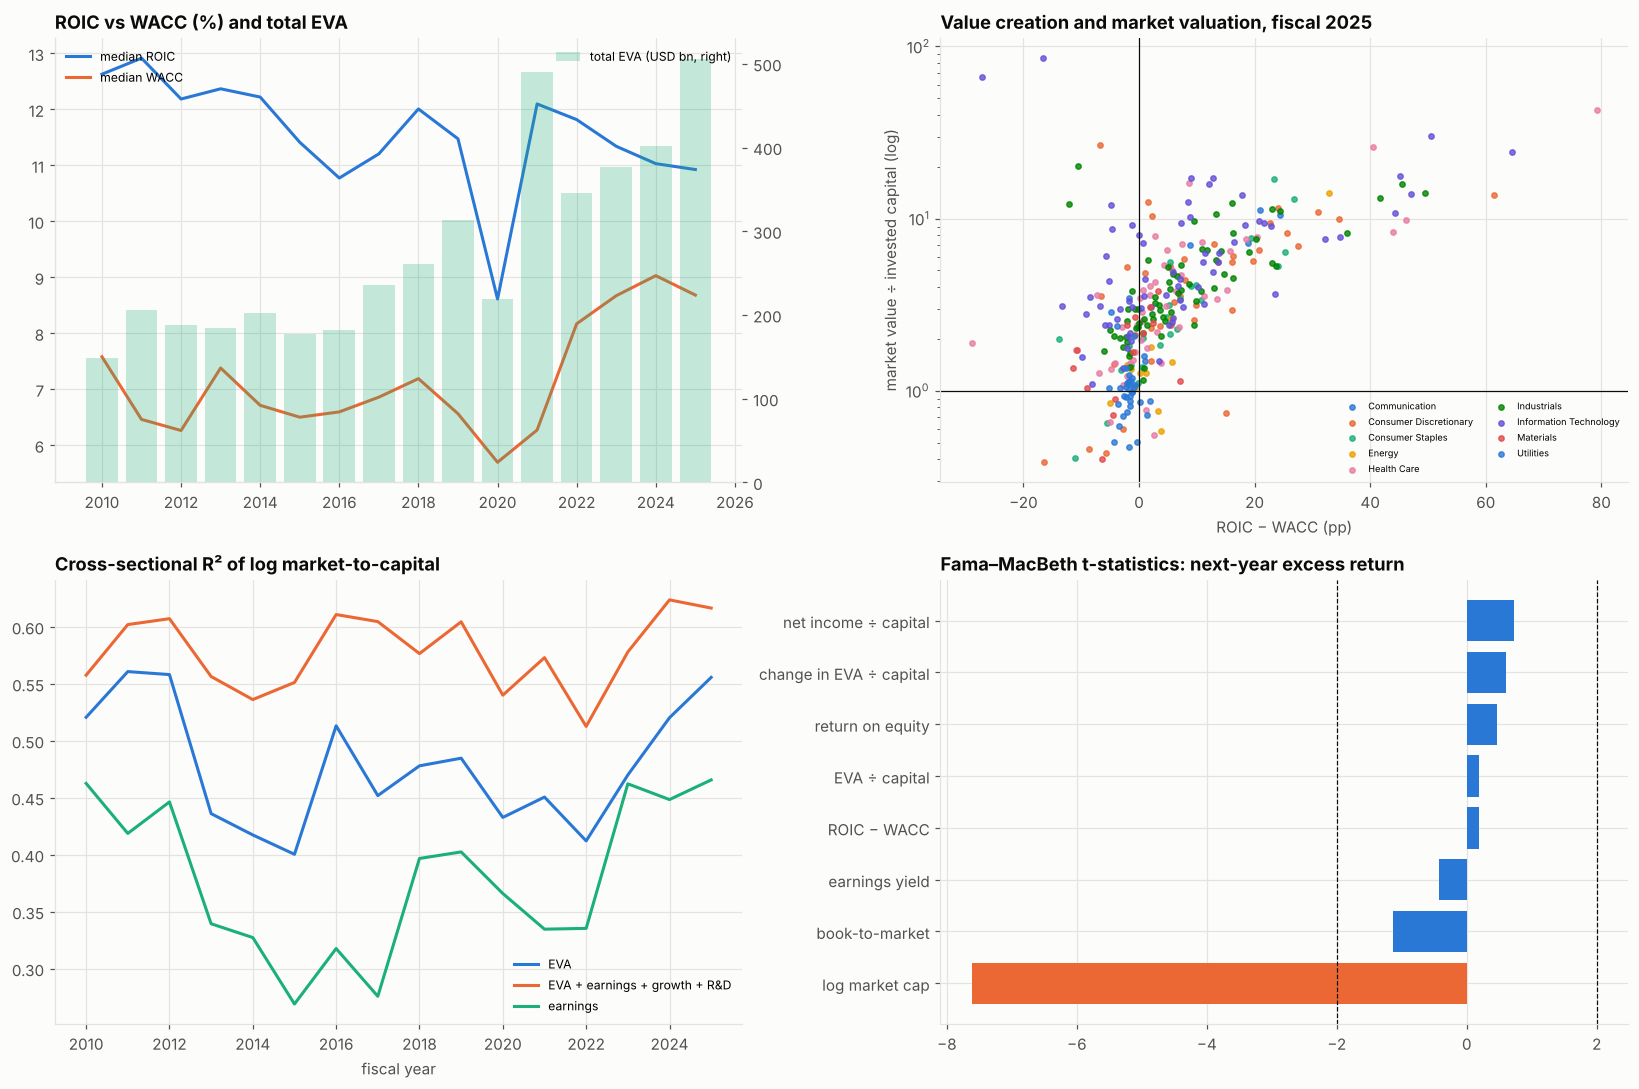

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
a = ax[0, 0]
a.plot(YR.index, YR.median_roic * 100, color=PALETTE[0], label="median ROIC")
a.plot(YR.index, YR.median_wacc * 100, color=PALETTE[1], label="median WACC")
a2 = a.twinx()
a2.bar(
    YR.index,
    YR.eva_total_bn,
    color=PALETTE[2],
    alpha=0.25,
    label="total EVA (USD bn, right)",
)
a2.grid(False)
a.set_title("ROIC vs WACC (%) and total EVA")
a.legend(loc="upper left", fontsize=8)
a2.legend(loc="upper right", fontsize=8)
a = ax[0, 1]
lv = last[(last.mtc > 0) & last.spread.between(-0.3, 0.8)]
for i_, (sec, g) in enumerate(lv.groupby("Sector")):
    a.scatter(
        g.spread * 100,
        g.mtc,
        s=12,
        color=PALETTE[i_ % len(PALETTE)],
        label=sec,
        alpha=0.8,
    )
a.set_yscale("log")
a.axvline(0, color=INK, lw=0.8)
a.axhline(1, color=INK, lw=0.8)
a.set_xlabel("ROIC − WACC (pp)")
a.set_ylabel("market value ÷ invested capital (log)")
a.set_title(f"Value creation and market valuation, fiscal {LFY}")
a.legend(fontsize=6, ncol=2)
a = ax[1, 0]
CSR2.plot(ax=a, color=PALETTE[:3])
a.set_xlabel("fiscal year")
a.set_title("Cross-sectional R² of log market-to-capital")
a.legend(fontsize=8)
a = ax[1, 1]
fmv = FM["t"].sort_values()
a.barh(
    fmv.index,
    fmv.values,
    color=[PALETTE[1] if abs(v) > 2 else PALETTE[0] for v in fmv.values],
)
a.axvline(2, color=INK, ls="--", lw=0.8)
a.axvline(-2, color=INK, ls="--", lw=0.8)
a.set_title("Fama–MacBeth t-statistics: next-year excess return")
fig.tight_layout()
save_fig(fig, "01_eva_mva_overview")
plt.show()

In [13]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        f"EVA by sector, fiscal {LFY} (USD bn)",
        "Share of companies with ROIC > WACC",
    ),
)
s_ = SECT.eva_bn.sort_values()
dash.add_trace(
    go.Bar(
        x=s_.values,
        y=s_.index,
        orientation="h",
        marker_color=[PALETTE[2] if v > 0 else PALETTE[1] for v in s_.values],
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=YR.index,
        y=YR.share_creating,
        mode="lines+markers",
        line_color=PALETTE[0],
    ),
    1,
    2,
)
dash.update_layout(
    height=600,
    width=1400,
    template="simple_white",
    showlegend=False,
    title="Economic Value Added in the S&P 500",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

*Filings and prices are refreshed weekly; values for the latest fiscal year can still change as late filers report.*

**Value creation is large, rising and concentrated.** Across 342 companies and 4,582 company-years, the median ROIC is 11.6% against a median WACC of 7.1%, and 71% of company-years earn more than their cost of capital. That share fell from 73–81% in 2010–2019 to 60–63% in 2022–2025, when higher rates lifted the median WACC from about 6.5% to 9%. Total EVA nevertheless rose from USD 148 bn in fiscal 2010 to USD 506 bn in 2025, and total MVA from USD 2.8 to 36.9 trillion.

| Fiscal 2025 | ROIC | WACC | EVA, USD bn | MVA, USD bn |
|---|---|---|---|---|
| Apple | 74% | 9.4% | 98 | 3,714 |
| NVIDIA | 103% | 13.6% | 96 | 4,404 |
| Alphabet | 34% | 9.4% | 78 | 3,509 |
| Microsoft | 30% | 9.3% | 73 | 3,354 |
| Meta | 29% | 9.9% | 38 | 1,515 |
| Intel | −1% | 8.9% | −14 | 82 |
| Ford | −5% | 11.2% | −23 | −84 |

- **Five technology companies produce three quarters of all EVA** (USD 383 bn of 506). Information technology contributes USD 309 bn. Utilities (3% of companies create value) and materials (33%) destroy it.
- **The biggest destroyers are capital-heavy**: Ford, EchoStar, Intel, General Motors, Kraft Heinz and CVS. Ford and GM carry their finance arms in invested capital, which overstates their capital. Tesla has negative EVA but USD 1.6 trillion of MVA: the market prices future, not current, EVA.

**Excess returns fade, but slowly.** The spread between ROIC and WACC has an AR(1) coefficient of 0.76 (half-life 2.6 years). Two-thirds of the top quintile is still there three years later, and 45% of the bottom quintile.

**R&D capitalisation matters less than its reputation.** It flips the sign of EVA in only 5% of company-years and lowers the median ROIC from 12.4% to 11.6%, because capital rises more than profit. Its effect depends on growth: EVA rises for Alphabet (78 → 82) and Meta (38 → 43), whose R&D is growing fast, and falls for Apple and Qualcomm.

**EVA explains market value better than earnings, but not returns.**

| Log market-to-capital | Earnings | EVA | EVA + earnings + growth + R&D |
|---|---|---|---|
| Cross-sectional R², median year | 0.38 | 0.47 | 0.58 |
| Out-of-time R² 2019–25: ridge / k-NN / LightGBM | 0.38 / 0.49 / 0.52 | 0.45 / 0.53 / 0.51 | 0.54 / 0.59 / 0.61 |

- **Levels:** the ROIC − WACC spread explains a quarter more of the cross-section of valuations than earnings measures do. Combining both with growth and R&D intensity works best, and LightGBM ranks valuations with a correlation of 0.82 out of time.
- **Returns:** no EVA or earnings measure predicts the next year's excess return after the 10-K. All Fama–MacBeth t-statistics are below 0.8 in absolute value, as Biddle, Bowen and Wallace found in 1997. The out-of-time models reach rank correlations of only 0.06–0.12, and EVA features are no better than earnings. Prices already reflect value creation once it is reported.
- **The strong size effect (t = −7.6) is survivorship.** Today's index members that were small ten years ago are, by construction, the ones that grew.

**Limitations.**
- **Universe and data:** today's S&P 500 members only; XBRL values as first filed, with some tags missing (Amazon reports "technology and infrastructure", not R&D); long-term investments and captive finance arms stay in invested capital.
- **Cost of capital:** a single 5% equity risk premium and CAPM betas; operating leases are in capital since 2019 while their cost stays in operating income.

In [14]:
cols_out = [
    "Name",
    "Sector",
    "fy",
    "end",
    "revenue",
    "ebit",
    "nopat",
    "ic_avg",
    "roic",
    "beta",
    "ke",
    "kd",
    "we",
    "wacc",
    "spread",
    "eva",
    "mva",
    "mtc",
]
E[cols_out].to_csv(OUT_DIR / "eva_mva_company_years.csv", index=False)
YR.to_csv(OUT_DIR / "eva_by_year.csv")
SECT.to_csv(OUT_DIR / "eva_by_sector_latest.csv")
TRANS.to_csv(OUT_DIR / "spread_quintile_transitions_3y.csv")
CSR2.to_csv(OUT_DIR / "market_value_cross_sectional_r2.csv")
MV_OOS.to_csv(OUT_DIR / "market_value_models_out_of_time.csv")
FM.to_csv(OUT_DIR / "fama_macbeth_returns.csv")
RET_OOS.to_csv(OUT_DIR / "return_models_out_of_time.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_eva_mva_overview.png, dashboard.html, dashboard.png, eva_by_sector_latest.csv, eva_by_year.csv, eva_mva_company_years.csv, fama_macbeth_returns.csv, market_value_cross_sectional_r2.csv, market_value_models_out_of_time.csv, return_models_out_of_time.csv, spread_quintile_transitions_3y.csv


## References

- Stewart, G. B. (1991). *The Quest for Value: The EVA Management Guide*. HarperBusiness.
- Biddle, G. C., Bowen, R. M., & Wallace, J. S. (1997). Does EVA beat earnings? Evidence on associations with stock returns and firm values. *Journal of Accounting and Economics*, 24(3), 301–336.
- Koller, T., Goedhart, M., & Wessels, D. (2020). *Valuation: Measuring and Managing the Value of Companies* (7th ed.). Wiley.
- Lev, B., & Sougiannis, T. (1996). The capitalization, amortization, and value-relevance of R&D. *Journal of Accounting and Economics*, 21(1), 107–138.
- Fama, E. F., & MacBeth, J. D. (1973). Risk, return, and equilibrium: Empirical tests. *Journal of Political Economy*, 81(3), 607–636.
- Blume, M. E. (1971). On the assessment of risk. *Journal of Finance*, 26(1), 1–10.
- Mauboussin, M. J., & Callahan, D. (2022). *Return on invested capital: How to calculate ROIC and handle common issues*. Morgan Stanley Investment Management, Consilient Research.
- U.S. Securities and Exchange Commission. *EDGAR XBRL company facts API*. https://www.sec.gov/edgar/sec-api-documentation
- BlackRock iShares. *iShares Core S&P 500 ETF (IVV) holdings*. https://www.ishares.com/us/products/239726/